# kino.instruments: the IFU forward model

**Scope note.** Like the other numbered notebooks, this is a "what works
today" demo, not the end-to-end kinematic-lensing showcase
(`04_one_galaxy_inference.ipynb`, still a scaffold pending Phase 5).

This one demonstrates `kino.instruments` (Phase 3): turning a lensed galaxy
scene (`kino.galaxy` + `kino.lensing`, Phases 1-2) into a realistic **IFU**
mock observation -- an actual telescope's aperture, AO/seeing PSF, spectral
resolution, pixelization onto a spaxel grid, and photon/sky/dark/read noise,
all driven by a YAML instrument config
(`kino/config/gmtifs.yaml`). See `kino/instruments/ifu.py`'s module
docstring and the "Instrument flux calibration" / "Instrument PSF/LSF" /
"Instrument noise / sky background" conventions in `CLAUDE.md` for the
physics this renderer implements.

## 0. Setup

In [1]:
from pathlib import Path

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np

import kino
from kino.galaxy import DiscGalaxy
from kino.instruments import IFU
from kino.lensing import apply_shear

rng = np.random.default_rng(seed=0)  # explicit, seeded RNG -- see CLAUDE.md conventions
CONFIG_PATH = Path("..") / "kino" / "config" / "gmtifs.yaml"
print("kino", kino.__version__)

kino 0.1.0.dev0


## 1. A lensed galaxy scene

The same kind of scene `02_shear_misalignment_demo.ipynb` builds: an
intrinsic `DiscGalaxy` with a reduced shear `(g1, g2)` applied to both its
surface brightness and its `Vlos` field. `z=0.68` is chosen so that
redshifted Halpha lands inside the instrument's spectral window in Section 2
below -- Halpha/[O III] kinematics of `z~0.4-1.5` discs is exactly the
GMTIFS science case in `README.md` Phase 7.

In [2]:
gal = DiscGalaxy(
    r_e=0.3,  # arcsec -- a compact, high-z disc, not a nearby-galaxy scale
    inc=55.0,
    pa=30.0,
    v_flat=180.0,
    r_t=0.2,
    z=0.68,
    sigma0=25.0,  # km/s, intrinsic turbulent dispersion
    flux=1.0,  # arbitrary units -- see the flux-calibration note in Section 3
)
scene = apply_shear(gal, g1=0.03, g2=-0.02)

LINE_WAVELENGTH = 0.6563 * u.um  # Halpha, rest frame
LINE_FLUX = 4e-16 * u.erg / u.s / u.cm**2  # intrinsic (unlensed) total line flux
print(f"observed-frame line centre (no peculiar velocity): {LINE_WAVELENGTH * (1 + gal.z):.4f}")

observed-frame line centre (no peculiar velocity): 1.1026 um


## 2. The instrument: detector, pixelization, PSF, LSF, throughput

`IFU.from_config` loads every "standard telescope quantity" -- spectral
resolution, spaxel size, array size, transmission curve, integration time --
plus the pieces a real photon-noise forecast also needs: aperture
(collecting area), a physical PSF (`galsim.OpticalPSF` diffraction convolved
with `galsim.Kolmogorov` seeing), sky background, and detector read
noise/dark current. `kino/config/gmtifs.yaml` is a fiducial GMTIFS-like
setup -- see that file's header comment for what's fiducial vs. real.

In [3]:
ifu = IFU.from_config(CONFIG_PATH)

fov_x = (ifu.nx * ifu.pixel_scale).to(u.arcsec)
fov_y = (ifu.ny * ifu.pixel_scale).to(u.arcsec)
total_exposure = (ifu.exposure_time * ifu.n_exposures).to(u.hour)
eff_area = ifu.effective_area.to(u.m**2)

print(f"pixelization : {ifu.pixel_scale}/spaxel, {ifu.nx}x{ifu.ny} -> {fov_x:.2f} x {fov_y:.2f}")
print(f"spectral     : {ifu.wavelength_min}-{ifu.wavelength_max}, {ifu.n_wave} channels")
print(f"             : R = {ifu.lsf.resolving_power}")
print(f"PSF          : seeing_fwhm = {ifu.psf.seeing_fwhm} (Kolmogorov) x OpticalPSF diffraction")
print(f"aperture     : {ifu.aperture_diameter} diameter, {ifu.obstruction_fraction:.0%} obstructed")
print(f"             : -> {eff_area:.1f} effective area")
print(f"detector     : read_noise = {ifu.detector.read_noise}")
print(f"             : dark_current = {ifu.detector.dark_current}")
print(f"exposure     : {ifu.exposure_time} x {ifu.n_exposures} = {total_exposure:.2f}")
print(f"sky          : {ifu.sky_electron_rate} per spaxel")

pixelization : 0.05 arcsec/spaxel, 80x40 -> 4.00 arcsec x 2.00 arcsec
spectral     : 1.1 um-1.14 um, 80 channels
             : R = 8000
PSF          : seeing_fwhm = 0.05 arcsec (Kolmogorov) x OpticalPSF diffraction
aperture     : 24.5 m diameter, 0% obstructed
             : -> 471.4 m2 effective area
detector     : read_noise = 5.0 electron
             : dark_current = 0.01 electron / s
exposure     : 600.0 s x 6 = 1.00 h
sky          : 3.0 electron / s per spaxel


## 3. The PSF: aperture diffraction + atmospheric seeing

`PSF.kernel` is what `IFU.observe` actually convolves the source with --
rasterised at the (oversampled) pixel scale, for the band's central
wavelength (achromatic within one cube, see `CLAUDE.md`). Comparing the
config's seeing against a diffraction-limited (`seeing_fwhm=0`) case makes
the AO correction's effect concrete.

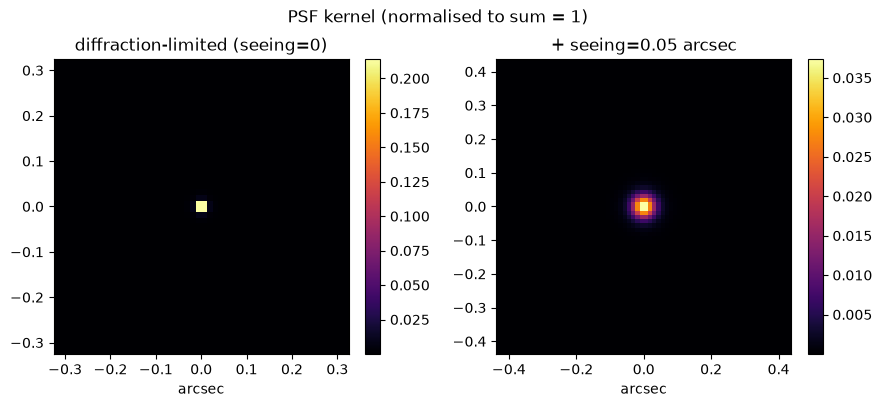

In [4]:
from kino.instruments import PSF

band_center = 0.5 * (ifu.wavelength_min + ifu.wavelength_max)
pix_over = ifu.pixel_scale / 4  # matches IFU's internal spatial oversampling

kernel_ao = ifu.psf.kernel(
    pix_over,
    wavelength=band_center,
    aperture_diameter=ifu.aperture_diameter,
    obscuration=ifu.obstruction_fraction,
)
kernel_diffraction_only = PSF(seeing_fwhm=0 * u.arcsec).kernel(
    pix_over,
    wavelength=band_center,
    aperture_diameter=ifu.aperture_diameter,
    obscuration=ifu.obstruction_fraction,
)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, kernel, title in zip(
    axes,
    [kernel_diffraction_only, kernel_ao],
    ["diffraction-limited (seeing=0)", f"+ seeing={ifu.psf.seeing_fwhm}"],
    strict=False,
):
    n = kernel.shape[0]
    half = n // 2 * pix_over.to_value(u.arcsec)
    im = ax.imshow(kernel, origin="lower", cmap="inferno", extent=[-half, half, -half, half])
    ax.set_title(title)
    ax.set_xlabel("arcsec")
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle("PSF kernel (normalised to sum = 1)")
fig.tight_layout()

## 4. Render the mock cube: pixelization in action

`IFU.observe` evaluates the scene on a finely oversampled grid, convolves
with the PSF above, bins each wavelength channel's line profile onto that
grid analytically (Gaussian CDF), then **bins down to the native spaxel
grid** -- the actual detector pixelization. `rng=None` returns the
noiseless expected-count cube (electrons).

total detected electrons (noiseless): 2.775e+09


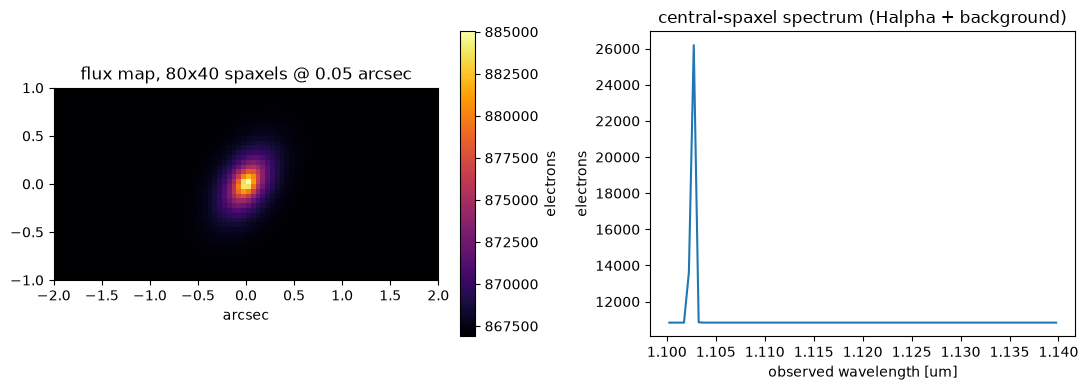

In [5]:
cube = ifu.observe(scene, line_flux=LINE_FLUX, line_wavelength=LINE_WAVELENGTH)

flux_map = cube.flux.sum(axis=0)
wavelength = cube.spectral_axis.to_value(u.um)
cy, cx = ifu.ny // 2, ifu.nx // 2
spectrum_centre = cube.flux[:, cy, cx]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
im0 = axes[0].imshow(
    flux_map,
    origin="lower",
    cmap="inferno",
    extent=[-fov_x.value / 2, fov_x.value / 2, -fov_y.value / 2, fov_y.value / 2],
)
axes[0].set_xlabel("arcsec")
axes[0].set_title(f"flux map, {ifu.nx}x{ifu.ny} spaxels @ {ifu.pixel_scale}")
fig.colorbar(im0, ax=axes[0], label="electrons", fraction=0.046)

axes[1].plot(wavelength, spectrum_centre)
axes[1].set_xlabel("observed wavelength [um]")
axes[1].set_ylabel("electrons")
axes[1].set_title("central-spaxel spectrum (Halpha + background)")
fig.tight_layout()
print(f"total detected electrons (noiseless): {cube.flux.sum():.3e}")

## 5. What pixelization + PSF blurring did to the intrinsic profile

For comparison, here is the same galaxy's **intrinsic, continuous**
surface brightness (`kino.galaxy`, no instrument at all -- the leftmost box
in the pipeline diagram in `README.md`), evaluated on a grid much finer than
a spaxel. The IFU-rendered map above is this same shape, magnified by the
applied shear, blurred by the PSF in Section 3, and binned down onto the
config's spaxel grid.

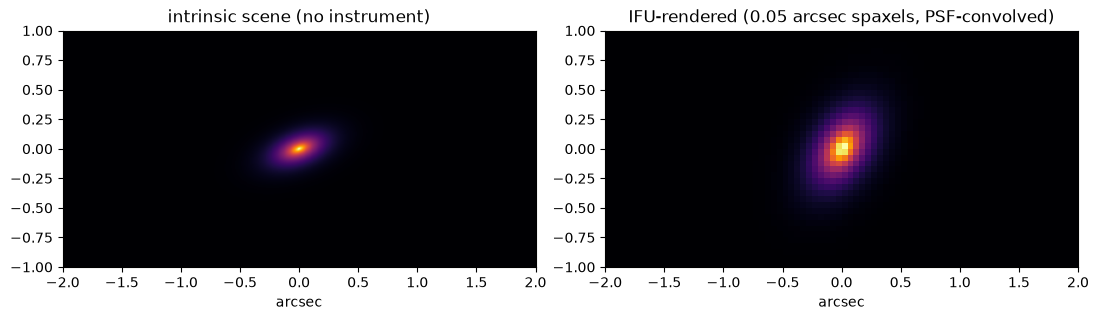

In [6]:
fine = np.linspace(-fov_x.value / 2, fov_x.value / 2, 400)
xx, yy = np.meshgrid(fine, fine)
intrinsic_map = scene.surface_brightness(xx, yy)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(
    intrinsic_map,
    origin="lower",
    cmap="inferno",
    extent=[-fov_x.value / 2, fov_x.value / 2, -fov_y.value / 2, fov_y.value / 2],
)
axes[0].set_title("intrinsic scene (no instrument)")
axes[0].set_xlabel("arcsec")
axes[1].imshow(
    flux_map,
    origin="lower",
    cmap="inferno",
    extent=[-fov_x.value / 2, fov_x.value / 2, -fov_y.value / 2, fov_y.value / 2],
)
axes[1].set_title(f"IFU-rendered ({ifu.pixel_scale} spaxels, PSF-convolved)")
axes[1].set_xlabel("arcsec")
fig.tight_layout()

## 6. Detector noise

The same config, observed with a seeded `rng`: Poisson source + sky +
dark-current shot noise, plus Gaussian read noise, on top of the noiseless
cube above. `Datacube.variance` is populated either way, so S/N doesn't
require drawing a realisation.

peak per-voxel S/N: 161.4


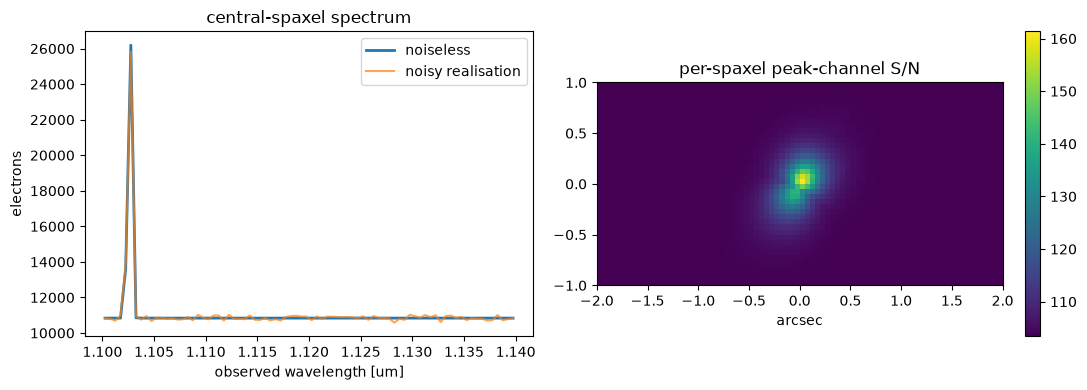

In [7]:
noisy = ifu.observe(scene, line_flux=LINE_FLUX, line_wavelength=LINE_WAVELENGTH, rng=rng)
noisy_spectrum_centre = noisy.flux[:, cy, cx]
snr_map = cube.flux / np.sqrt(cube.variance)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(wavelength, spectrum_centre, label="noiseless", lw=2)
axes[0].plot(wavelength, noisy_spectrum_centre, label="noisy realisation", alpha=0.7)
axes[0].set_xlabel("observed wavelength [um]")
axes[0].set_ylabel("electrons")
axes[0].set_title("central-spaxel spectrum")
axes[0].legend()

im1 = axes[1].imshow(
    snr_map.max(axis=0),
    origin="lower",
    cmap="viridis",
    extent=[-fov_x.value / 2, fov_x.value / 2, -fov_y.value / 2, fov_y.value / 2],
)
axes[1].set_xlabel("arcsec")
axes[1].set_title("per-spaxel peak-channel S/N")
fig.colorbar(im1, ax=axes[1], fraction=0.046)
fig.tight_layout()
print(f"peak per-voxel S/N: {snr_map.max():.1f}")

## 7. Sweeping the instrument, not the galaxy

Two of `IFU`'s "standard quantities" directly trade against each other in a
real proposal: worse seeing blurs the image; lower spectral resolution
blurs the line. Same scene, same detector, just the instrument config
changed -- the kind of sweep a forecast is actually for.

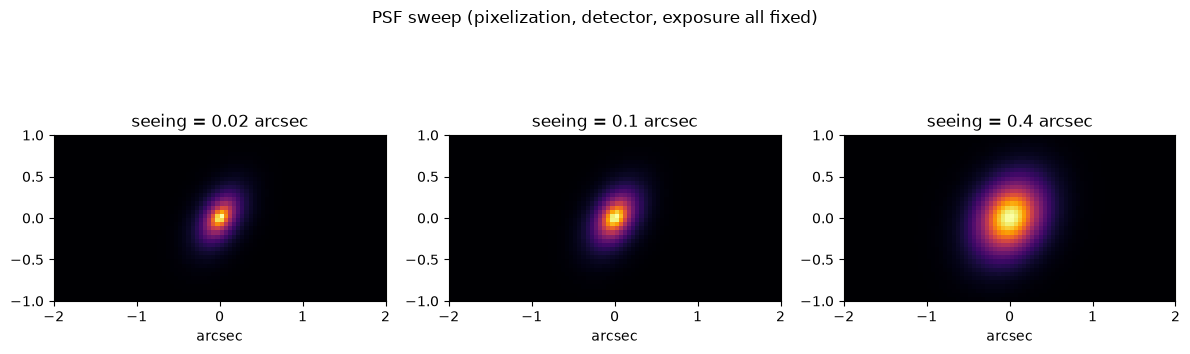

In [8]:
import dataclasses

seeings = [0.02, 0.1, 0.4] * u.arcsec
fig, axes = plt.subplots(1, len(seeings), figsize=(4 * len(seeings), 4))
for ax, seeing in zip(axes, seeings, strict=False):
    ifu_s = dataclasses.replace(ifu, psf=PSF(seeing_fwhm=seeing))
    c = ifu_s.observe(scene, line_flux=LINE_FLUX, line_wavelength=LINE_WAVELENGTH)
    ax.imshow(
        c.flux.sum(axis=0),
        origin="lower",
        cmap="inferno",
        extent=[-fov_x.value / 2, fov_x.value / 2, -fov_y.value / 2, fov_y.value / 2],
    )
    ax.set_title(f"seeing = {seeing}")
    ax.set_xlabel("arcsec")
fig.suptitle("PSF sweep (pixelization, detector, exposure all fixed)")
fig.tight_layout()

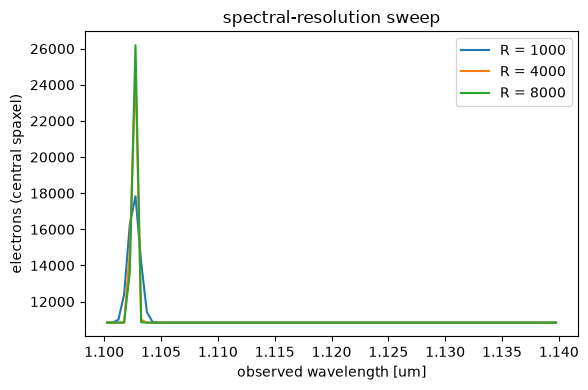

In [9]:
from kino.instruments import LSF

resolving_powers = [1000.0, 4000.0, 8000.0]
fig, ax = plt.subplots(figsize=(6, 4))
for R in resolving_powers:
    ifu_r = dataclasses.replace(ifu, lsf=LSF(resolving_power=R))
    c = ifu_r.observe(scene, line_flux=LINE_FLUX, line_wavelength=LINE_WAVELENGTH)
    ax.plot(c.spectral_axis.to_value(u.um), c.flux[:, cy, cx], label=f"R = {R:.0f}")
ax.set_xlabel("observed wavelength [um]")
ax.set_ylabel("electrons (central spaxel)")
ax.set_title("spectral-resolution sweep")
ax.legend()
fig.tight_layout()

## What's next

- `kino.analysis.moments.compute_moment_maps` (Phase 3/6): extract flux/Vlos/dispersion
  moment maps, with noise, from a `Datacube` like the one rendered here --
  see `tests/analysis/test_moment_maps.py` and
  `notebooks/00_kinms_datacube_demo.ipynb` section 2 for the same kind of
  moment-0/moment-1 collapse done by hand.
- `kino.instruments.slit.SlitSpectrograph` (Phase 3): the same
  `PSF`/`LSF`/`Throughput`/`Detector` building blocks, dispersed onto a
  2-D spectrum through a slit instead of a spaxel grid, with slit losses and
  misalignment falling directly out of the rendering geometry -- see
  `kino/config/gmacs.yaml` for a fiducial config.
- `kino.mocks` (Phase 4): batch-generate cubes like this one from a YAML
  galaxy-population + shear-field catalogue, with FITS/HDF5 writers and
  provenance.
- `kino.inference` (Phase 5): fit a model back to a noisy cube like the one
  in Section 6 and recover `(g1, g2)` -- the eventual subject of
  `04_one_galaxy_inference.ipynb`.